# 第 07 课｜风险与方差

> **数据身份**：固定随机种子生成的模拟教学数据，不是真实证券行情。  
> **环境**：`pkm-quant` · Python 3.11 · 默认离线运行。  
> **课程原始材料**：`07_youtube-77BCwkiGHhQ/index.html`  
> **所属模块**：P1-M2 · 收益、时间价值与风险

## 本节量化问题

标准差能说明多少风险，又遗漏了什么？

## 准确定义与策略报告位置

方差和标准差刻画围绕均值的离散程度；年化波动率通常用日收益标准差乘以 √252。

- **核心关系**：样本方差 s²=Σ(R_t-R̄)²/(n-1)；年化波动率 σ_ann=s_daily√252。
- **写入报告**：波动、下行风险和回撤
- **P2 衔接**：P2 第 36、40、48 课：滚动窗口、图表和厚尾诊断。


## 运行环境与数据契约

先确认项目、数据目录和数据身份。后续联网数据源必须通过适配层进入，不能改变本 Notebook 的研究计算口径。

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "fixtures").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "fixtures"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RANDOM_SEED = 365
print("项目:", ROOT)
print("数据:", DATA_DIR)
print("数据身份: 固定随机种子生成的模拟教学数据，不是真实证券行情")


项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations
数据: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations/data/fixtures
数据身份: 固定随机种子生成的模拟教学数据，不是真实证券行情


## 从日收益得到方差、波动和回撤

样本标准差使用 `ddof=1`。年化波动假设收益频率稳定且近似独立；最大回撤从累计净值的历史峰值计算。

In [2]:
daily = pd.read_csv(DATA_DIR / "daily_prices.csv", parse_dates=["date"])
market = daily.loc[daily["symbol"] == "SIM_MARKET"].set_index("date")["adj_close"]
returns = market.pct_change(fill_method=None).dropna()

daily_variance = returns.var(ddof=1)
annual_volatility = returns.std(ddof=1) * np.sqrt(252)
nav = (1.0 + returns).cumprod()
drawdown = nav / nav.cummax() - 1.0

print(f"日方差: {daily_variance:.8f}")
print(f"年化波动: {annual_volatility:.2%}")
print(f"最大回撤: {drawdown.min():.2%}")

日方差: 0.00007698
年化波动: 13.93%
最大回撤: -25.41%


## 滚动波动随市场状态变化

20 日窗口只使用当日及之前的 20 个观测；它是历史估计，不是未来波动承诺。

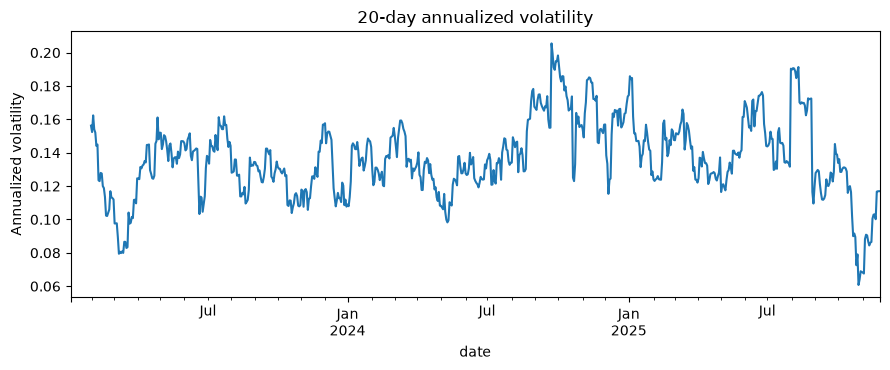

In [3]:
rolling_volatility = returns.rolling(window=20, min_periods=20).std(ddof=1) * np.sqrt(252)
ax = rolling_volatility.plot(figsize=(9, 3.8), title="20-day annualized volatility")
ax.set_ylabel("Annualized volatility")
plt.tight_layout()
plt.show()

## 方法边界与阶段验收

波动不是全部风险；收益厚尾、自相关、流动性和最大回撤需要额外诊断。

完成本课后应能：

1. 不看课程材料准确解释核心概念和公式符号；
2. 用小样本手工核对 Notebook 的关键结果；
3. 说明结果能支持什么判断、不能支持什么判断；
4. 指出它在策略报告中的位置，以及仍缺少的数据、成本或稳健性证据。
